# Automotive and RV Domain Analysis

This notebook investigates whether the IBM Sales Win/Loss extract supports a focused **B2B automotive parts, accessories and recreational-vehicle supplies** framing. It is separate from the finalized IBM baseline in `07_ibm_final_model.ipynb`.

This stage inspects product labels, defines a target-independent scope, and prepares comparable partitions. **No model is trained in this scope-review stage.**

## 1. Evidence and limitations

The repository contains no verified IBM source documentation, data dictionary, industry statement, dates, or code definitions. Product labels can support a **label-based IBM subset**, but cannot establish that the records come from a real automotive supplier or that inputs were available before the outcome.

This remains an internal IBM-record investigation, not external validation for an automotive organization.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42
id_column = "Opportunity Number"
target_column = "Opportunity Result"

repository_root = Path.cwd()
if repository_root.name == "notebooks":
    repository_root = repository_root.parent
raw_df = pd.read_csv(repository_root / "datasets" / "IBM-sales-opportunity.csv", keep_default_na=False, na_values=[""])
deduplicated_df = raw_df.drop_duplicates()
cleaned_df = deduplicated_df.loc[~deduplicated_df[id_column].duplicated(keep=False)].copy()
cleaned_df["target"] = cleaned_df[target_column].map({"Won": 1, "Loss": 0})
assert cleaned_df[id_column].is_unique and cleaned_df["target"].notna().all()
print(f"Cleaned IBM population: {len(cleaned_df):,} opportunities.")

Cleaned IBM population: 77,692 opportunities.


## 2. Inspect the actual product labels

These tables show every product group/subgroup and their resolved outcomes. Outcomes are descriptive only: they are **not** used to decide which categories belong in the proposed automotive/RV scope.

In [2]:
product_mapping = cleaned_df[["Supplies Group", "Supplies Subgroup"]].drop_duplicates()
display(product_mapping.sort_values(["Supplies Group", "Supplies Subgroup"]).reset_index(drop=True))

category_summary = cleaned_df.groupby("Supplies Subgroup", observed=True).agg(
    opportunities=("target", "size"), Won=("target", "sum"),
).assign(Loss=lambda table: table["opportunities"] - table["Won"], Won_rate=lambda table: table["Won"] / table["opportunities"])
display(category_summary.sort_values("opportunities", ascending=False).round(4))

,Supplies Group,Supplies Subgroup
0,Car Accessories,Batteries & Accessories
1,Car Accessories,Exterior Accessories
2,Car Accessories,Garage & Car Care
3,Car Accessories,Interior Accessories
4,Car Accessories,Replacement Parts
5,Car Accessories,Towing & Hitches
6,Car Electronics,Car Electronics
7,Performance & Non-auto,Motorcycle Parts
8,Performance & Non-auto,Performance Parts
9,Performance & Non-auto,Shelters & RV


,opportunities,Won,Loss,Won_rate
Supplies Subgroup,,,,
Motorcycle Parts,15128,3632,11496,0.2401
Exterior Accessories,13828,3486,10342,0.2521
Garage & Car Care,9702,2766,6936,0.2851
Shelters & RV,9569,1780,7789,0.1860
Batteries & Accessories,9146,1856,7290,0.2029
Replacement Parts,7603,2018,5585,0.2654
Interior Accessories,5495,843,4652,0.1534
Towing & Hitches,3804,576,3228,0.1514
Performance Parts,2534,397,2137,0.1567


## 3. Proposed automotive/RV inclusion rule — review before training

Include the subgroups whose labels or parent group explicitly identify automotive, motorcycle, tires/wheels, or RV supplies: Batteries & Accessories, Exterior Accessories, Garage & Car Care, Interior Accessories, Replacement Parts, Towing & Hitches, Car Electronics, Tires & Wheels, Motorcycle Parts, and Shelters & RV.

Exclude **Performance Parts** for now. Its parent group is `Performance & Non-auto`, and no repository source defines whether it is automotive, recreational, or another market. The rule uses product names only, before inspecting outcomes.

In [3]:
automotive_subgroups = [
    "Batteries & Accessories", "Exterior Accessories", "Garage & Car Care",
    "Interior Accessories", "Replacement Parts", "Towing & Hitches",
    "Car Electronics", "Tires & Wheels", "Motorcycle Parts", "Shelters & RV",
]
automotive_df = cleaned_df.loc[cleaned_df["Supplies Subgroup"].isin(automotive_subgroups)].copy()
assert "Performance Parts" not in automotive_df["Supplies Subgroup"].unique()

display(pd.DataFrame({
    "opportunities": [len(automotive_df)],
    "Won": [automotive_df["target"].sum()],
    "Loss": [(automotive_df["target"] == 0).sum()],
    "Won prevalence": [automotive_df["target"].mean()],
}).round(4))

automotive_summary = automotive_df.groupby("Supplies Subgroup", observed=True).agg(
    opportunities=("target", "size"), Won=("target", "sum"),
).assign(Loss=lambda table: table["opportunities"] - table["Won"], Won_rate=lambda table: table["Won"] / table["opportunities"])
display(automotive_summary.sort_values("opportunities", ascending=False).round(4))

for column in ["Opportunity Amount USD", "Revenue From Client Past Two Years", "Route To Market", "Client Size By Revenue", "Client Size By Employee Count"]:
    print(f"\n{column}")
    display(automotive_df.groupby(column, observed=True).agg(opportunities=("target", "size"), Won_rate=("target", "mean")).sort_values("opportunities", ascending=False).head(12).round(4))

,opportunities,Won,Loss,Won prevalence
0,75158,17103,58055,0.2276


,opportunities,Won,Loss,Won_rate
Supplies Subgroup,,,,
Motorcycle Parts,15128,3632,11496,0.2401
Exterior Accessories,13828,3486,10342,0.2521
Garage & Car Care,9702,2766,6936,0.2851
Shelters & RV,9569,1780,7789,0.1860
Batteries & Accessories,9146,1856,7290,0.2029
Replacement Parts,7603,2018,5585,0.2654
Interior Accessories,5495,843,4652,0.1534
Towing & Hitches,3804,576,3228,0.1514
Tires & Wheels,606,74,532,0.1221



Opportunity Amount USD


,opportunities,Won_rate
Opportunity Amount USD,,
50000,4566,0.0561
100000,3570,0.0462
20000,3318,0.1127
10000,3285,0.1333
30000,2740,0.0931
150000,2322,0.0349
200000,2183,0.0426
0,1948,0.1586
15000,1830,0.1738



Revenue From Client Past Two Years


...

,opportunities,Won_rate
Route To Market,,
Fields Sales,35807,0.1860
Reseller,33536,0.2785
Other,2758,0.1885
Telesales,2457,0.2214
Telecoverage,600,0.0633



Client Size By Revenue


,opportunities,Won_rate
Client Size By Revenue,,
1,57344,0.2305
5,5078,0.1942
3,4567,0.2303
4,4464,0.2247
2,3705,0.2273



Client Size By Employee Count


,opportunities,Won_rate
Client Size By Employee Count,,
1,57222,0.2308
5,4894,0.1902
3,4753,0.2295
2,4353,0.2267
4,3936,0.2256


## 4. Proposed comparison and evaluation method — no training yet

If this scope is approved, compare three prespecified input specifications on the same automotive/RV-labelled records:

1. **Lean 3:** amount, prior-client revenue, route.
2. **Portable 5:** Lean 3 plus the two client-size fields.
3. **Automotive product candidate:** Lean 3 plus `Supplies Subgroup`. `Supplies Group` is not added because subgroup determines it.

For each specification, compare the same fixed Logistic Regression, Random Forest, and XGBoost settings from Notebook 07. Select using validation ROC-AUC, AP, Brier, product-field availability, and simplicity. Only then evaluate the frozen finalist on the automotive subset of the existing test membership. The finalized Notebook 07 Lean 3 pipeline will also be scored on those same automotive test records. This remains a repeated internal evaluation because the IBM test partition has already been inspected.

A separate automotive model should be retained only if subgroup information gives a meaningful, stable improvement. Otherwise, the simpler finalized Lean 3 model remains preferable.

In [4]:
# Recreate Notebook 07 membership on the full population, then filter each partition.
development_df, full_test_df = train_test_split(cleaned_df, test_size=0.20, stratify=cleaned_df["target"], random_state=RANDOM_SEED)
full_fit_df, full_validation_df = train_test_split(development_df, test_size=0.25, stratify=development_df["target"], random_state=RANDOM_SEED + 1)
full_train_df, full_calibration_df = train_test_split(full_fit_df, test_size=1 / 6, stratify=full_fit_df["target"], random_state=RANDOM_SEED + 2)

automotive_partitions = {
    "Training": full_train_df.loc[full_train_df["Supplies Subgroup"].isin(automotive_subgroups)],
    "Calibration": full_calibration_df.loc[full_calibration_df["Supplies Subgroup"].isin(automotive_subgroups)],
    "Validation": full_validation_df.loc[full_validation_df["Supplies Subgroup"].isin(automotive_subgroups)],
    "Test": full_test_df.loc[full_test_df["Supplies Subgroup"].isin(automotive_subgroups)],
}
partition_summary = pd.DataFrame([
    {"partition": name, "opportunities": len(frame), "Won prevalence": frame["target"].mean()}
    for name, frame in automotive_partitions.items() if name != "Test"
]).set_index("partition")
display(partition_summary.round(4))
print("The automotive test membership is created but sealed: it is not displayed, scored, or used for selection.")

,opportunities,Won prevalence
partition,,
Training,37586,0.2279
Calibration,7517,0.2270
Validation,15025,0.2270


The automotive test membership is created but sealed: it is not displayed, scored, or used for selection.


## Scope review decision required

The proposed subset contains **75,158** opportunities: **17,103 Won** and **58,055 Loss**. It excludes only the ambiguous `Performance Parts` subgroup, so it is a product-label scope rather than a sharply separate population.

The scope is approved for the following validation-only feature-comparison stage. Final automotive test evaluation, threshold selection, calibration decisions, and deployment remain out of scope.

# Automotive feature engineering and validation comparison

This stage tests whether product hierarchy, customer profile, or geography provides useful additional signal for the automotive/RV-labelled subset. Every candidate uses only fields intended to represent information available when an opportunity is created or scored; IBM timing and category definitions still require verification.

## 5. Candidate inputs and product hierarchy

Amount represents commercial value; prior-client revenue represents relationship history; route represents sales channel; group/subgroup represent product information; client-size fields describe the customer; and region is geographic context. These are credible CRM concepts, but IBM codes and prediction-time availability are not proven.

The code checks whether subgroup determines group. If it does, group is a broader label and subgroup is more detailed; both are still tested together rather than being automatically dropped. A future CRM should store both for product selection, filtering, and reporting even if the model uses only one.

In [5]:
amount_column = "Opportunity Amount USD"
feature_sets = {
    "Lean 3": [amount_column, "Revenue From Client Past Two Years", "Route To Market"],
    "Automotive 4 — Subgroup": [amount_column, "Revenue From Client Past Two Years", "Route To Market", "Supplies Subgroup"],
    "Automotive 5 — Group + Subgroup": [amount_column, "Revenue From Client Past Two Years", "Route To Market", "Supplies Group", "Supplies Subgroup"],
    "Automotive 7 — Product + Profile": [amount_column, "Revenue From Client Past Two Years", "Route To Market", "Supplies Group", "Supplies Subgroup", "Client Size By Revenue", "Client Size By Employee Count"],
    "Automotive 8 — Product + Profile + Region": [amount_column, "Revenue From Client Past Two Years", "Route To Market", "Supplies Group", "Supplies Subgroup", "Client Size By Revenue", "Client Size By Employee Count", "Region"],
}

subgroup_group_counts = automotive_df.groupby("Supplies Subgroup")["Supplies Group"].nunique()
assert subgroup_group_counts.eq(1).all(), "A subgroup unexpectedly maps to multiple groups."
print("Each observed Supplies Subgroup belongs to exactly one Supplies Group.")

feature_membership = pd.DataFrame(index=list(dict.fromkeys(sum(feature_sets.values(), []))))
for name, columns in feature_sets.items():
    feature_membership[name] = feature_membership.index.isin(columns)
display(feature_membership.replace({True: "Yes", False: "-"}))

for columns in feature_sets.values():
    assert automotive_df[columns].isna().sum().eq(0).all()
print("All planned automotive inputs are complete in this extract; unknown real-world history must not be replaced with zero.")

Each observed Supplies Subgroup belongs to exactly one Supplies Group.


,Lean 3,Automotive 4 — Subgroup,Automotive 5 — Group + Subgroup,Automotive 7 — Product + Profile,Automotive 8 — Product + Profile + Region
Opportunity Amount USD,Yes,Yes,Yes,Yes,Yes
Revenue From Client Past Two Years,Yes,Yes,Yes,Yes,Yes
Route To Market,Yes,Yes,Yes,Yes,Yes
Supplies Subgroup,-,Yes,Yes,Yes,Yes
Supplies Group,-,-,Yes,Yes,Yes
Client Size By Revenue,-,-,-,Yes,Yes
Client Size By Employee Count,-,-,-,Yes,Yes
Region,-,-,-,-,Yes


All planned automotive inputs are complete in this extract; unknown real-world history must not be replaced with zero.


## 6. Training-only preprocessing and fixed models

Amount is transformed with `log1p` and scaled. Every other candidate field is treated as a category and one-hot encoded. The preprocessing is fitted inside each pipeline on automotive training data only, so validation records cannot influence category lists or scaling.

The three algorithms and settings match Notebook 07: Logistic Regression is a simple baseline; Random Forest and XGBoost can model nonlinear patterns. These are fixed comparisons, not hyperparameter tuning.

In [6]:
import numpy as np
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

def build_preprocessor(feature_columns):
    """Return an unfitted transformer for one approved feature specification."""
    categorical_columns = [column for column in feature_columns if column != amount_column]
    return ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_columns),
        ("amount", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("scale", StandardScaler())]), [amount_column]),
    ])

models = {
    "Logistic Regression": LogisticRegression(C=1.0, solver="lbfgs", max_iter=1500, random_state=RANDOM_SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=30, max_features=0.8, n_jobs=2, random_state=RANDOM_SEED),
    "XGBoost": XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.05, min_child_weight=10, subsample=0.9, colsample_bytree=0.9, reg_lambda=5, objective="binary:logistic", eval_metric="logloss", tree_method="hist", n_jobs=2, random_state=RANDOM_SEED),
}

def probability_metrics(actual, probabilities):
    """Return ranking and probability-quality scores for Won = 1."""
    return {
        "ROC-AUC": roc_auc_score(actual, probabilities),
        "Average Precision": average_precision_score(actual, probabilities),
        "Brier Score": brier_score_loss(actual, probabilities),
    }

## 7. Train the 15 automotive candidates on matched validation records

The automotive training and validation partitions are fixed from the approved scope stage. Each of the five feature specifications is combined with each of the three algorithms: 15 learned candidates. The automotive test partition is deliberately not accessed in this stage.

The training-prevalence baseline predicts the automotive training Won rate for every validation opportunity. It shows whether the models add useful information beyond the historical average.

In [7]:
automotive_train_df = automotive_partitions["Training"]
automotive_validation_df = automotive_partitions["Validation"]
y_train = automotive_train_df["target"]
y_validation = automotive_validation_df["target"]
training_prevalence = y_train.mean()
baseline_probabilities = np.full(len(y_validation), training_prevalence)

comparison_rows = [{"Feature Set": "No features", "Model": "Training prevalence", **probability_metrics(y_validation, baseline_probabilities)}]
fitted_models = {}
validation_probabilities = {}

for feature_set_name, columns in feature_sets.items():
    for model_name, model in models.items():
        pipeline = Pipeline([("preprocess", build_preprocessor(columns)), ("model", clone(model))])
        # fit learns only from automotive training records; validation rows are scored afterwards.
        pipeline.fit(automotive_train_df[columns], y_train)
        probabilities = pipeline.predict_proba(automotive_validation_df[columns])[:, 1]
        key = (feature_set_name, model_name)
        fitted_models[key] = pipeline
        validation_probabilities[key] = probabilities
        comparison_rows.append({"Feature Set": feature_set_name, "Model": model_name, **probability_metrics(y_validation, probabilities)})

validation_results = pd.DataFrame(comparison_rows)
learned_results = validation_results.loc[validation_results["Model"] != "Training prevalence"].sort_values(["Brier Score", "ROC-AUC"], ascending=[True, False])
display(pd.concat([validation_results.iloc[[0]], learned_results], ignore_index=True).round(5))
assert len(fitted_models) == 15
print("Completed 15 automotive training/validation comparisons; the automotive test partition remains unused.")

,Feature Set,Model,ROC-AUC,Average Precision,Brier Score
0,No features,Training prevalence,0.50000,0.22696,0.17545
1,Automotive 8 — Product + Profile + Region,Random Forest,0.82145,0.60796,0.12911
2,Automotive 5 — Group + Subgroup,Random Forest,0.82083,0.60763,0.12921
3,Lean 3,Random Forest,0.82218,0.60361,0.12925
4,Automotive 7 — Product + Profile,Random Forest,0.82067,0.60596,0.12935
5,Automotive 4 — Subgroup,Random Forest,0.81934,0.60620,0.12960
6,Automotive 5 — Group + Subgroup,XGBoost,0.81676,0.60238,0.13062
7,Automotive 7 — Product + Profile,XGBoost,0.81622,0.60312,0.13064
8,Lean 3,XGBoost,0.81684,0.60100,0.13069
9,Automotive 4 — Subgroup,XGBoost,0.81579,0.60232,0.13076


Completed 15 automotive training/validation comparisons; the automotive test partition remains unused.


## 8. Feature comparisons and fair broader-model benchmark

The first table compares the five specifications within each algorithm. The second benchmark refits the already-finalized Notebook 07 Lean 3 Random Forest on the broader IBM training membership, then scores it on the **same automotive validation rows**. This distinguishes a broad-population model from a model trained only on automotive/RV-labelled records.

This is still validation-only evidence. Different-population headline metrics from Notebook 07 and Notebook 08 must not be compared directly.

In [8]:
metric_columns = ["ROC-AUC", "Average Precision", "Brier Score"]
feature_comparison = learned_results.pivot(index="Feature Set", columns="Model", values=metric_columns).reindex(list(feature_sets))
display(feature_comparison.round(5))

best_by_algorithm = learned_results.drop_duplicates("Model").set_index("Model")
display(best_by_algorithm.loc[list(models), ["Feature Set"] + metric_columns].round(5))

lean_columns = feature_sets["Lean 3"]
broader_lean_pipeline = Pipeline([("preprocess", build_preprocessor(lean_columns)), ("model", clone(models["Random Forest"]))])
# This reproduces the frozen Notebook 07 Lean 3 training scope, not a new automotive model.
broader_lean_pipeline.fit(full_train_df[lean_columns], full_train_df["target"])
broader_lean_probabilities = broader_lean_pipeline.predict_proba(automotive_validation_df[lean_columns])[:, 1]
broader_benchmark = pd.DataFrame([
    {"Training population": "Automotive/RV subset", "Model": "Lean 3 Random Forest", **probability_metrics(y_validation, validation_probabilities[("Lean 3", "Random Forest")])},
    {"Training population": "Broader IBM population", "Model": "Notebook 07 Lean 3 Random Forest", **probability_metrics(y_validation, broader_lean_probabilities)},
])
display(broader_benchmark.round(5))

ROC-AUC                \
Model                                     Logistic Regression Random Forest   
Feature Set                                                                   
Lean 3                                                0.72644       0.82218   
Automotive 4 — Subgroup                               0.72763       0.81934   
Automotive 5 — Group + Subgroup                       0.72758       0.82083   
Automotive 7 — Product + Profile                      0.72665       0.82067   
Automotive 8 — Product + Profile + Region             0.72813       0.82145   

                                                     Average Precision  \
Model                                      XGBoost Logistic Regression   
Feature Set                                                              
Lean 3                                     0.81684             0.49738   
Automotive 4 — Subgroup                    0.81579             0.49918   
Automotive 5 — Group + Subgroup            0.81676             0.49904   
Automotive 7 — Product + Profile           0.81622             0.49934   
Automotive 8 — Product + Profile + Region  0.81568             0.50314   

                                                                  \
Model                                     Random Forest  XGBoost   
Feature Set                                                        
Lean 3                                          0.60361  0.60100   
Automotive 4 — Subgroup                         0.60620  0.60232   
Automotive 5 — Group + Subgroup                 0.60763  0.60238   
Automotive 7 — Product + Profile                0.60596  0.60312   
Automotive 8 — Product + Profile + Region       0.60796  0.60414   

                                                  Brier Score                \
Model                                     Logistic Regression Random Forest   
Feature Set                                                                   
Lean 3                                                0.14852       0.12925   
Automotive 4 — Subgroup                               0.14798       0.12960   
Automotive 5 — Group + Subgroup                       0.14798       0.12921   
Automotive 7 — Product + Profile                      0.14796       0.12935   
Automotive 8 — Product + Profile + Region             0.14774       0.12911   

                                                    
Model                                      XGBoost  
Feature Set                                         
Lean 3                                     0.13069  
Automotive 4 — Subgroup                    0.13076  
Automotive 5 — Group + Subgroup            0.13062  
Automotive 7 — Product + Profile           0.13064  
Automotive 8 — Product + Profile + Region  0.13077

,Feature Set,ROC-AUC,Average Precision,Brier Score
Model,,,,
Logistic Regression,Automotive 8 — Product + Profile + Region,0.72813,0.50314,0.14774
Random Forest,Automotive 8 — Product + Profile + Region,0.82145,0.60796,0.12911
XGBoost,Automotive 5 — Group + Subgroup,0.81676,0.60238,0.13062


,Training population,Model,ROC-AUC,Average Precision,Brier Score
0,Automotive/RV subset,Lean 3 Random Forest,0.82218,0.60361,0.12925
1,Broader IBM population,Notebook 07 Lean 3 Random Forest,0.82159,0.60353,0.12928


## 9. Small validation-set feature-importance check

For the best tree-based automotive candidate, permute one original business field at a time in validation data and measure the increase in Brier loss. A larger increase means the fitted model relied more on that field. This is not causal evidence: shuffling can create unrealistic combinations and correlated fields can share importance.

In [9]:
from sklearn.inspection import permutation_importance

tree_results = learned_results.loc[learned_results["Model"].isin(["Random Forest", "XGBoost"])].copy()
leading_tree_row = tree_results.iloc[0]
leading_tree_key = (leading_tree_row["Feature Set"], leading_tree_row["Model"])
leading_tree_columns = feature_sets[leading_tree_key[0]]
leading_tree_pipeline = fitted_models[leading_tree_key]

importance_result = permutation_importance(
    leading_tree_pipeline, automotive_validation_df[leading_tree_columns], y_validation,
    scoring="neg_brier_score", n_repeats=5, random_state=RANDOM_SEED, n_jobs=2,
)
importance_table = pd.DataFrame({
    "Business feature": leading_tree_columns,
    "Mean Brier-loss increase when shuffled": importance_result.importances_mean,
}).sort_values("Mean Brier-loss increase when shuffled", ascending=False)
print(f"Feature importance for: {leading_tree_key[0]} / {leading_tree_key[1]}")
display(importance_table.round(5))

Feature importance for: Automotive 8 — Product + Profile + Region / Random Forest


,Business feature,Mean Brier-loss increase when shuffled
1,Revenue From Client Past Two Years,0.04373
0,Opportunity Amount USD,0.03729
2,Route To Market,0.00684
7,Region,0.00191
4,Supplies Subgroup,0.00155
3,Supplies Group,0.00022
6,Client Size By Employee Count,0.00011
5,Client Size By Revenue,0.00009


## Provisional recommendation — generated from validation evidence

The next cell identifies the lowest-Brier automotive candidate and prints its validation metrics, required inputs, and comparison with the broader Notebook 07 Lean 3 benchmark. Review that output using the practical 0.005 ROC-AUC and 0.002 Brier guidance alongside product relevance, input availability, supported categories, and implementation complexity.

This is not a final automotive model decision. Calibration, classification threshold selection, automotive test evaluation, local SHAP explanations, and deployment remain intentionally deferred.

In [10]:
provisional_row = learned_results.iloc[0]
provisional_feature_set = provisional_row["Feature Set"]
provisional_model = provisional_row["Model"]
print(f"Lowest validation Brier candidate: {provisional_feature_set} / {provisional_model}")
print(f"ROC-AUC: {provisional_row['ROC-AUC']:.5f}; AP: {provisional_row['Average Precision']:.5f}; Brier: {provisional_row['Brier Score']:.5f}")
print("Required inputs:", ", ".join(feature_sets[provisional_feature_set]))
print("No automotive test rows, threshold, calibration decision, or deployment artifacts were used in this stage.")

Lowest validation Brier candidate: Automotive 8 — Product + Profile + Region / Random Forest
ROC-AUC: 0.82145; AP: 0.60796; Brier: 0.12911
Required inputs: Opportunity Amount USD, Revenue From Client Past Two Years, Route To Market, Supplies Group, Supplies Subgroup, Client Size By Revenue, Client Size By Employee Count, Region
No automotive test rows, threshold, calibration decision, or deployment artifacts were used in this stage.


## Provisional validation recommendation

Random Forest remains preferable to XGBoost and Logistic Regression across these automotive/RV-labelled validation comparisons. Automotive 8 has the lowest Brier (**0.12911**) and highest AP (**0.60796**), but compared with Automotive Lean 3 its Brier improvement is only **0.00014** and its ROC-AUC is lower by **0.00073**. This is well inside the project’s practical 0.002 Brier and 0.005 ROC-AUC guidance.

The small validation-set importance check also ranks prior-client revenue, amount, and route far above region, subgroup, group, and customer-size fields. Product subgroup has a small measured contribution; group and customer-size fields contribute very little after the other inputs are known.

These validation results show that Lean 3 remains a strong simpler alternative. The CRM should collect product group and subgroup for automotive/RV product selection, reporting, filtering, and future local-model evidence. The final case-study feature decision is documented after the frozen evaluation, rather than being inferred from a small validation-score difference alone.

The broader-population Notebook 07 Lean 3 Random Forest scores almost identically on the same automotive validation rows (ROC-AUC 0.82159, AP 0.60353, Brier 0.12928) compared with automotive-subset Lean 3 (0.82218, 0.60361, 0.12925). This does not establish that either transfers to a real automotive organization.

No automotive test rows, threshold selection, calibration decision, local SHAP analysis, or deployment work has been performed. Those actions require a separate decision.

# Finalize Automotive 5 before test evaluation

The primary case-study model is now frozen as **Random Forest — Automotive 5**: Opportunity Amount USD, Revenue From Client Past Two Years, Route To Market, Supplies Group, and Supplies Subgroup. Its validation ROC-AUC/AP/Brier are 0.82083 / 0.60763 / 0.12921.

This is a deliberate automotive domain-alignment choice. It does not materially outperform Lean 3: AP and Brier are slightly better, while ROC-AUC is slightly lower. Region, client-size fields, competitor information, IDs, sales-cycle fields, and outcome-derived fields are not part of this frozen contract.

## 10. Automotive limited-history fallback

The primary requires prior-client revenue. This fallback is trained without it, using amount, route, product group, and product subgroup. It is for genuinely unavailable or incomplete account history only; verified zero history remains a known category for the primary once IBM code definitions are confirmed. It is not a new-customer or early-stage model.

In [11]:
primary_feature_set = "Automotive 5 — Group + Subgroup"
primary_key = (primary_feature_set, "Random Forest")
primary_pipeline = fitted_models[primary_key]
primary_validation_probabilities = validation_probabilities[primary_key]
fallback_columns = [amount_column, "Route To Market", "Supplies Group", "Supplies Subgroup"]
fallback_pipeline = Pipeline([("preprocess", build_preprocessor(fallback_columns)), ("model", clone(models["Random Forest"]))])
fallback_pipeline.fit(automotive_train_df[fallback_columns], y_train)
fallback_validation_probabilities = fallback_pipeline.predict_proba(automotive_validation_df[fallback_columns])[:, 1]

fallback_validation = pd.DataFrame([
    {"Model": "Training prevalence", **probability_metrics(y_validation, baseline_probabilities)},
    {"Model": "Automotive 5 primary", **probability_metrics(y_validation, primary_validation_probabilities)},
    {"Model": "Automotive limited-history fallback", **probability_metrics(y_validation, fallback_validation_probabilities)},
])
display(fallback_validation.round(5))

fallback_retained = brier_score_loss(y_validation, fallback_validation_probabilities) < brier_score_loss(y_validation, baseline_probabilities) - 0.002
print("Fallback retained for unavailable history:", fallback_retained)

,Model,ROC-AUC,Average Precision,Brier Score
0,Training prevalence,0.50000,0.22696,0.17545
1,Automotive 5 primary,0.82083,0.60763,0.12921
2,Automotive limited-history fallback,0.77858,0.49058,0.14464


Fallback retained for unavailable history: True


## 11. Automotive 5 probability calibration and threshold

Calibration checks whether predicted chances match observed Won rates across groups. A sigmoid mapping is fitted only on the separate calibration partition and judged on validation data. The classification threshold is also chosen only from validation F1; it is not the sales-prioritization rule.

In [12]:
from sklearn.metrics import precision_recall_curve

primary_columns = feature_sets[primary_feature_set]
calibration_df = automotive_partitions["Calibration"]
calibration_probabilities = primary_pipeline.predict_proba(calibration_df[primary_columns])[:, 1]
epsilon = 1e-6

def probability_log_odds(probabilities):
    """Convert clipped probabilities into one log-odds input for sigmoid calibration."""
    clipped = np.clip(probabilities, epsilon, 1 - epsilon)
    return np.log(clipped / (1 - clipped))

calibrator = LogisticRegression(C=1e6, solver="lbfgs", max_iter=1000, random_state=RANDOM_SEED)
calibrator.fit(probability_log_odds(calibration_probabilities).reshape(-1, 1), calibration_df["target"])
sigmoid_validation_probabilities = calibrator.predict_proba(probability_log_odds(primary_validation_probabilities).reshape(-1, 1))[:, 1]

calibration_comparison = pd.DataFrame([
    {"Probability version": "Raw", **probability_metrics(y_validation, primary_validation_probabilities)},
    {"Probability version": "Sigmoid", **probability_metrics(y_validation, sigmoid_validation_probabilities)},
])
display(calibration_comparison.round(5))

raw_brier = brier_score_loss(y_validation, primary_validation_probabilities)
sigmoid_brier = brier_score_loss(y_validation, sigmoid_validation_probabilities)
use_sigmoid = sigmoid_brier < raw_brier - 0.0005
selected_validation_probabilities = sigmoid_validation_probabilities if use_sigmoid else primary_validation_probabilities
calibration_decision = "Sigmoid retained" if use_sigmoid else "Raw probabilities retained"
print(calibration_decision)

precision, recall, thresholds = precision_recall_curve(y_validation, selected_validation_probabilities)
f1_values = np.nan_to_num(2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1]), nan=0.0)
classification_threshold = thresholds[f1_values == f1_values.max()].max()
print(f"Validation F1 threshold: {classification_threshold:.5f}; F1: {f1_values.max():.5f}")

,Probability version,ROC-AUC,Average Precision,Brier Score
0,Raw,0.82083,0.60763,0.12921
1,Sigmoid,0.82083,0.60763,0.12919


Raw probabilities retained
Validation F1 threshold: 0.23168; F1: 0.58081


### Validation reliability and frozen decisions

The table below shows the selected probability version by ten ranges. Counts, average prediction, and observed Won rate make sparse or mismatched ranges visible before the test partition is opened. After this point, feature set, algorithm, calibration, fallback rule, and threshold are frozen.

In [13]:
validation_reliability = pd.DataFrame({"actual Won": y_validation.to_numpy(), "probability": selected_validation_probabilities})
validation_reliability["Probability range"] = pd.cut(validation_reliability["probability"], bins=np.linspace(0, 1, 11), include_lowest=True)
validation_reliability = validation_reliability.groupby("Probability range", observed=False).agg(
    opportunities=("actual Won", "size"), average_prediction=("probability", "mean"), actual_won_rate=("actual Won", "mean"),
).reset_index()
validation_reliability["prediction_minus_observed"] = validation_reliability["average_prediction"] - validation_reliability["actual_won_rate"]
display(validation_reliability.round(4))

,Probability range,opportunities,average_prediction,actual_won_rate,prediction_minus_observed
0,"(-0.001, 0.1]",5356,0.0583,0.0519,0.0063
1,"(0.1, 0.2]",4012,0.1443,0.1348,0.0094
2,"(0.2, 0.3]",1774,0.2441,0.2931,-0.0490
3,"(0.3, 0.4]",1224,0.3582,0.3562,0.0020
4,"(0.4, 0.5]",980,0.4502,0.4653,-0.0151
5,"(0.5, 0.6]",493,0.5400,0.5477,-0.0076
6,"(0.6, 0.7]",271,0.6513,0.6679,-0.0166
7,"(0.7, 0.8]",399,0.7504,0.7368,0.0136
8,"(0.8, 0.9]",392,0.8412,0.8138,0.0274
9,"(0.9, 1.0]",124,0.9218,0.9274,-0.0056


## 12. Frozen automotive test evaluation

All choices are frozen before this first automotive test scoring. This is a repeated internal IBM-data evaluation: the automotive test partition was held out from Notebook 08 training, but its parent IBM partition had already been inspected in Notebook 07. Results below will not change the model choice.

In [14]:
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

automotive_test_df = automotive_partitions["Test"]
raw_test_probabilities = primary_pipeline.predict_proba(automotive_test_df[primary_columns])[:, 1]
test_probabilities = calibrator.predict_proba(probability_log_odds(raw_test_probabilities).reshape(-1, 1))[:, 1] if use_sigmoid else raw_test_probabilities
assert np.logical_and(test_probabilities >= 0, test_probabilities <= 1).all()
test_predictions = (test_probabilities >= classification_threshold).astype(int)

test_metrics = {
    **probability_metrics(automotive_test_df["target"], test_probabilities),
    "Test Won prevalence": automotive_test_df["target"].mean(),
    "Training prevalence Brier": brier_score_loss(automotive_test_df["target"], np.full(len(automotive_test_df), training_prevalence)),
    "Precision": precision_score(automotive_test_df["target"], test_predictions),
    "Recall": recall_score(automotive_test_df["target"], test_predictions),
    "F1": f1_score(automotive_test_df["target"], test_predictions),
    "Minimum probability": test_probabilities.min(),
    "Maximum probability": test_probabilities.max(),
}
display(pd.DataFrame([test_metrics]).round(5))

test_confusion = confusion_matrix(automotive_test_df["target"], test_predictions, labels=[0, 1])
display(pd.DataFrame(test_confusion, index=["Actual Loss", "Actual Won"], columns=["Predicted Loss", "Predicted Won"]))

,ROC-AUC,Average Precision,Brier Score,Test Won prevalence,Training prevalence Brier,Precision,Recall,F1,Minimum probability,Maximum probability
0,0.81441,0.60221,0.13079,0.22774,0.17588,0.48559,0.70903,0.57642,0.00435,0.9471


,Predicted Loss,Predicted Won
Actual Loss,9036,2571
Actual Won,996,2427


### Test reliability and fallback evaluation

Calibration asks whether probabilities correspond to observed outcomes across enough similar records. The same table structure is used for the frozen primary and, if retained, the fallback. Empty or small ranges are limitations, not evidence of perfect reliability.

In [15]:
def reliability_table(actual, probabilities):
    frame = pd.DataFrame({"actual Won": actual.to_numpy(), "probability": probabilities})
    frame["Probability range"] = pd.cut(frame["probability"], bins=np.linspace(0, 1, 11), include_lowest=True)
    table = frame.groupby("Probability range", observed=False).agg(
        opportunities=("actual Won", "size"), average_prediction=("probability", "mean"), actual_won_rate=("actual Won", "mean"),
    ).reset_index()
    table["prediction_minus_observed"] = table["average_prediction"] - table["actual_won_rate"]
    return table

display(reliability_table(automotive_test_df["target"], test_probabilities).round(4))

if fallback_retained:
    fallback_test_probabilities = fallback_pipeline.predict_proba(automotive_test_df[fallback_columns])[:, 1]
    fallback_test_metrics = {
        **probability_metrics(automotive_test_df["target"], fallback_test_probabilities),
        "Minimum probability": fallback_test_probabilities.min(), "Maximum probability": fallback_test_probabilities.max(),
    }
    display(pd.DataFrame([fallback_test_metrics]).round(5))
    display(reliability_table(automotive_test_df["target"], fallback_test_probabilities).round(4))

,Probability range,opportunities,average_prediction,actual_won_rate,prediction_minus_observed
0,"(-0.001, 0.1]",5383,0.0582,0.0589,-0.0006
1,"(0.1, 0.2]",3956,0.1446,0.1274,0.0172
2,"(0.2, 0.3]",1727,0.2446,0.3086,-0.0640
3,"(0.3, 0.4]",1270,0.3590,0.3362,0.0227
4,"(0.4, 0.5]",1000,0.4491,0.4700,-0.0209
5,"(0.5, 0.6]",466,0.5418,0.5107,0.0311
6,"(0.6, 0.7]",313,0.6532,0.6645,-0.0113
7,"(0.7, 0.8]",408,0.7512,0.7353,0.0159
8,"(0.8, 0.9]",383,0.8455,0.8094,0.0361
9,"(0.9, 1.0]",124,0.9220,0.9355,-0.0135


,ROC-AUC,Average Precision,Brier Score,Minimum probability,Maximum probability
0,0.76995,0.48559,0.14636,0.00304,0.73633


,Probability range,opportunities,average_prediction,actual_won_rate,prediction_minus_observed
0,"(-0.001, 0.1]",3435,0.0540,0.0515,0.0024
1,"(0.1, 0.2]",4970,0.1451,0.1338,0.0113
2,"(0.2, 0.3]",2225,0.2451,0.2297,0.0154
3,"(0.3, 0.4]",1757,0.3510,0.4058,-0.0548
4,"(0.4, 0.5]",1347,0.4475,0.4365,0.0110
5,"(0.5, 0.6]",953,0.5438,0.5719,-0.0281
6,"(0.6, 0.7]",304,0.6459,0.6414,0.0045
7,"(0.7, 0.8]",39,0.7186,0.7436,-0.0250
8,"(0.8, 0.9]",0,NaN,NaN,NaN
9,"(0.9, 1.0]",0,NaN,NaN,NaN


## 13. SHAP explanations for Automotive 5

SHAP divides each predicted Won probability into a reference probability plus feature contributions. Positive contributions raise the prediction; negative contributions lower it. It explains the trained model's associations, not what would cause an opportunity to be Won.

/home/emmanuel/.venvs/opportunity-scoring/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


 61%|============        | 244/400 [00:11<00:07]       

 66%|=============       | 266/400 [00:12<00:06]       

 73%|===============     | 291/400 [00:13<00:04]       

 79%|================    | 316/400 [00:14<00:03]       

 84%|=================   | 336/400 [00:15<00:02]       

 90%|==================  | 358/400 [00:16<00:01]       

 95%|=================== | 381/400 [00:17<00:00]       

,mean absolute SHAP value
Revenue From Client Past Two Years,0.10608
Opportunity Amount USD,0.09829
Route To Market,0.02898
Supplies Subgroup,0.00854
Supplies Group,0.00335


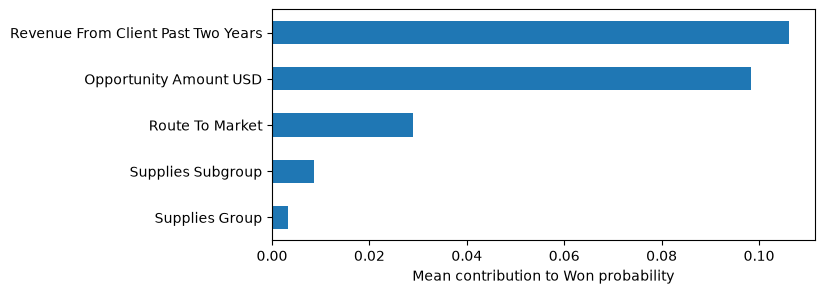

In [16]:
import matplotlib.pyplot as plt
import shap

shap_sample = automotive_validation_df[primary_columns].sample(n=200, random_state=142)
shap_background = automotive_train_df[primary_columns].sample(n=100, random_state=142)
preprocessor = primary_pipeline.named_steps["preprocess"]
forest_model = primary_pipeline.named_steps["model"]
sample_transformed = preprocessor.transform(shap_sample)
background_transformed = preprocessor.transform(shap_background)
encoded_feature_names = preprocessor.get_feature_names_out()

explainer = shap.TreeExplainer(forest_model, data=background_transformed, feature_perturbation="interventional", model_output="probability")
shap_output = explainer(sample_transformed)
won_shap_values = shap_output.values[:, :, 1] if shap_output.values.ndim == 3 else shap_output.values
won_base_values = shap_output.base_values[:, 1] if np.ndim(shap_output.base_values) == 2 else shap_output.base_values
shap_probabilities = primary_pipeline.predict_proba(shap_sample)[:, 1]
assert np.allclose(won_base_values + won_shap_values.sum(axis=1), shap_probabilities, atol=1e-6)

feature_owner = [next(column for column in primary_columns if encoded_name.endswith(column) or encoded_name.startswith(f"categorical__{column}_")) for encoded_name in encoded_feature_names]
business_shap = pd.DataFrame({column: won_shap_values[:, np.array(feature_owner) == column].sum(axis=1) for column in primary_columns})
global_shap_importance = business_shap.abs().mean().sort_values(ascending=False).rename("mean absolute SHAP value").to_frame()
display(global_shap_importance.round(5))
global_shap_importance.sort_values("mean absolute SHAP value").plot.barh(legend=False, figsize=(7, 3), xlabel="Mean contribution to Won probability")
plt.show()

### Contribution summary and local explanation

The box plot shows how each original business feature moves predictions across the sample. The local record is selected near the median predicted probability without using its outcome; its table separates contributions raising and lowering the probability.

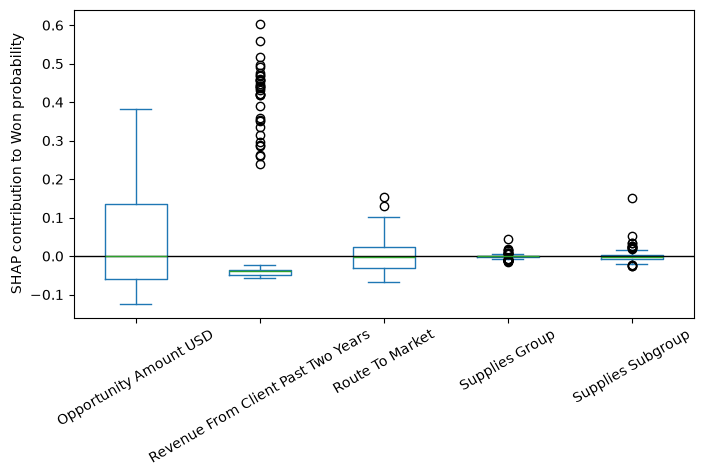

,Opportunity Amount USD,Revenue From Client Past Two Years,Route To Market,Supplies Group,Supplies Subgroup
25861,60000,0,Reseller,Performance & Non-auto,Motorcycle Parts


,contribution to Won probability
Route To Market,0.03769
Supplies Group,-0.00007
Supplies Subgroup,-0.00544
Opportunity Amount USD,-0.01694
Revenue From Client Past Two Years,-0.05145


SHAP reference probability: 0.19699
Model Won probability: 0.16078


In [17]:
business_shap.plot.box(figsize=(8, 4), rot=30)
plt.axhline(0, color="black", linewidth=1)
plt.ylabel("SHAP contribution to Won probability")
plt.show()

local_position = np.abs(shap_probabilities - np.median(shap_probabilities)).argmin()
local_record = shap_sample.iloc[[local_position]]
local_contributions = business_shap.iloc[local_position].sort_values(ascending=False).rename("contribution to Won probability").to_frame()
display(local_record)
display(local_contributions.round(5))
print(f"SHAP reference probability: {won_base_values[local_position]:.5f}")
print(f"Model Won probability: {shap_probabilities[local_position]:.5f}")

## 14. Export the frozen inference artifacts

This cell serializes the already-fitted primary and retained fallback from this notebook run. It does not select, tune, calibrate, or refit a different model. Before saving, it checks the frozen validation/test values and confirms that reloaded artifacts return exactly the same probabilities on fixed reference records.

In [18]:
import json
import joblib

artifact_directory = repository_root / 'models' / 'automotive_v1'
artifact_directory.mkdir(parents=True, exist_ok=True)
primary_artifact_path = artifact_directory / 'automotive_5_primary.joblib'
fallback_artifact_path = artifact_directory / 'automotive_limited_history_fallback.joblib'
metadata_path = artifact_directory / 'metadata.json'

# Confirm this reconstructed run still matches the frozen raw-probability evidence before export.
validation_check = probability_metrics(y_validation, primary_pipeline.predict_proba(automotive_validation_df[primary_columns])[:, 1])
test_check = probability_metrics(automotive_test_df['target'], primary_pipeline.predict_proba(automotive_test_df[primary_columns])[:, 1])
for observed, expected in zip(validation_check.values(), [0.82083, 0.60763, 0.12921]):
    assert np.isclose(observed, expected, atol=1e-5)
for observed, expected in zip(test_check.values(), [0.81441, 0.60221, 0.13079]):
    assert np.isclose(observed, expected, atol=1e-5)

primary_preprocessor = primary_pipeline.named_steps['preprocess']
fallback_preprocessor = fallback_pipeline.named_steps['preprocess']
primary_encoder = primary_preprocessor.named_transformers_['categorical']
fallback_encoder = fallback_preprocessor.named_transformers_['categorical']
primary_scaler = primary_preprocessor.named_transformers_['amount'].named_steps['scale']
assert primary_scaler.n_features_in_ == 1 and list(primary_pipeline.named_steps['model'].classes_) == [0, 1]

metadata = {
    'model_version': 'automotive_v1',
    'probability_output': 'raw Won probability; class 1 is Won',
    'classification_threshold_for_academic_reporting': 0.23168,
    'primary_features': primary_columns,
    'fallback_features': fallback_columns,
    'amount_preprocessing': ['log1p', 'StandardScaler'],
    'random_forest': primary_pipeline.named_steps['model'].get_params(),
    'primary_encoder_categories': {column: values.tolist() for column, values in zip(primary_preprocessor.transformers_[0][2], primary_encoder.categories_)},
    'fallback_encoder_categories': {column: values.tolist() for column, values in zip(fallback_preprocessor.transformers_[0][2], fallback_encoder.categories_)},
    'primary_transformed_feature_order': primary_preprocessor.get_feature_names_out().tolist(),
    'validation_metrics': {key: round(value, 5) for key, value in validation_check.items()},
    'test_metrics': {key: round(value, 5) for key, value in test_check.items()},
}

joblib.dump(primary_pipeline, primary_artifact_path)
joblib.dump(fallback_pipeline, fallback_artifact_path)
metadata_path.write_text(json.dumps(metadata, indent=2) + '\n', encoding='utf-8')

loaded_primary = joblib.load(primary_artifact_path)
loaded_fallback = joblib.load(fallback_artifact_path)
primary_reference = automotive_validation_df[primary_columns].iloc[:10]
fallback_reference = automotive_validation_df[fallback_columns].iloc[:10]
assert np.allclose(primary_pipeline.predict_proba(primary_reference), loaded_primary.predict_proba(primary_reference), atol=1e-12)
assert np.allclose(fallback_pipeline.predict_proba(fallback_reference), loaded_fallback.predict_proba(fallback_reference), atol=1e-12)
print('Exported and round-trip verified:', primary_artifact_path, fallback_artifact_path)
categorical_columns = list(primary_preprocessor.transformers_[0][2])
display(pd.DataFrame({'categorical feature': categorical_columns, 'learned categories': [values.tolist() for values in primary_encoder.categories_]}))
display(pd.DataFrame([{
    'numerical feature': amount_column,
    'preprocessing': 'log1p then StandardScaler',
    'scaler mean': primary_scaler.mean_[0],
    'scaler scale': primary_scaler.scale_[0],
}]).round(5))

Exported and round-trip verified: /home/emmanuel/University/4.2E/ICS_project_2/Opportunity-scoring-ISproject/models/automotive_v1/automotive_5_primary.joblib /home/emmanuel/University/4.2E/ICS_project_2/Opportunity-scoring-ISproject/models/automotive_v1/automotive_limited_history_fallback.joblib


,categorical feature,learned categories
0,Revenue From Client Past Two Years,"[0, 1, 2, 3, 4]"
1,Route To Market,"[Fields Sales, Other, Reseller, Telecoverage, ..."
2,Supplies Group,"[Car Accessories, Car Electronics, Performance..."
3,Supplies Subgroup,"[Batteries & Accessories, Car Electronics, Ext..."


,numerical feature,preprocessing,scaler mean,scaler scale
0,Opportunity Amount USD,log1p then StandardScaler,10.30944,2.27161


## Final Automotive Model Decision

Automotive 5 Random Forest is the selected IBM automotive/RV case-study model. It uses `Opportunity Amount USD`, `Revenue From Client Past Two Years`, `Route To Market`, `Supplies Group`, and `Supplies Subgroup`. Its selection deliberately preserves the product hierarchy central to the proposed automotive opportunity-management workflow; it is not a claim that five inputs are statistically superior to Lean 3. Its validation ROC-AUC/AP/Brier are **0.82083 / 0.60763 / 0.12921**.

On the frozen automotive test subset, the raw primary model obtains **0.81441 ROC-AUC**, **0.60221 AP**, and **0.13079 Brier**, compared with **0.17588** Brier for predicting the training win prevalence for every record. At the validation-selected F1 threshold of **0.23168**, precision/recall/F1 are **0.48559 / 0.70903 / 0.57642**. Sigmoid calibration changed validation Brier only from 0.12921 to 0.12919, below the prespecified 0.0005 threshold, so raw probabilities are retained. The limited-history fallback is retained only for genuinely unavailable or incomplete prior-client history: its validation ROC-AUC/AP/Brier are **0.77858 / 0.49058 / 0.14464** and its frozen-test values are **0.76995 / 0.48559 / 0.14636**. Product group and subgroup should be collected together in the CRM, although subgroup determines group in this IBM extract and the two fields may be partly redundant.

The CRM must derive prior-client revenue from verified account transaction records; salespeople must not guess IBM-style history codes. Complete records showing zero qualifying revenue may use the verified zero category in the primary model, subject to confirmation of IBM code meanings. Unknown or incomplete history must never be replaced with `0`; it may use the retained fallback only when all fallback inputs are valid. An early-stage opportunity does not establish either a new customer or zero prior purchases.

SHAP additivity was checked in Won-probability units. Across representative validation records, the largest mean absolute contributions are prior-client revenue (0.10608), amount (0.09829), route (0.02898), subgroup (0.00854), and group (0.00335). SHAP shows learned associations, not causal effects.

The model estimates the probability that an automotive/RV-labelled IBM opportunity will eventually be Won, based on its approved input representation. It is a repeated internal IBM-data evaluation, not external validation for an arbitrary automotive supplier. IBM source provenance, code meanings, prediction-time availability, compatible real-world category mappings, and organization-specific validation remain required before deployment.